# Visualize Layer-Skip Diagnostics

This Visualize notebook loads the cached data produced by `Generate-layer-skip-data.ipynb` together with the original model's layerwise graph-spectral summaries and generates the comparison figure for **Preliminary Layerwise Intervention Analysis** in the appendix. It compares the paired change in normalized absolute next-state extrapolation error after bypassing each of the 28 Llama-3.2-3B layers with the original model's effective spectral support, $\exp(\mathrm{SE})$, high-frequency energy ratio (HFER), and normalized Fiedler value at $N = 2000$ tokens.

Rows show chaotic inputs (logistic $r = 3.9$, $r = 4.0$, and Lorenz), periodic inputs with periods 2, 4, and 8, and periodic inputs with periods 16, 32, and 64. Black curves show the paired error changes on the left axes; colored curves show the graph-spectral diagnostics on the right axes. Curves are arithmetic means, and shading shows $\pm 1$ sample standard deviation across the 60 realizations pooled within each group, including both within-family and between-family variation. Positive error changes indicate worse extrapolation after skipping a layer.

The included graph-spectral summaries are copied from the caches produced by the three Generate notebooks in `../Layerwise-graph-spectral-diagnostics/Across-layers/`.


Set imports, relative cache and figure paths, diagnostic labels, and display settings.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
import numpy as np
import pandas as pd

# Run from this notebook's directory; load cached data and save figures locally
CACHE_DIR = Path("cache")
FIGURE_DIR = Path("figures")

# Match the error normalization and ensemble size in the generation notebooks
ERROR_NORMALIZATION = 950.0 - 50.0
DIAGNOSTIC_RUNS_PER_INPUT = 20

# Input grouping and original-model graph-spectral diagnostic styles
CHAOTIC_INPUTS = ["Logistic r=3.9", "Logistic r=4.0", "Lorenz"]
METRICS = [
    ("fiedler", "fiedler_per_layer.npz", r"$\lambda_2^{(\ell)}$", "#4C6FFF", "D"),
    ("hfer", "hfer_per_layer.npz", r"$\mathrm{HFER}^{(\ell)}$", "#18A999", "^"),
    ("effective_modes", "spectral_entropy_per_layer.npz", r"$\exp(\mathrm{SE}^{(\ell)})$", "#D95F5F", "s"),
]

# Use five evenly spaced ticks on each diagnostic axis
METRIC_TICKS = {
    "effective_modes": np.linspace(0.0, 500.0, 5),
    "hfer": np.linspace(0.0, 0.4, 5),
    "fiedler": np.linspace(0.0, 0.6, 5),
}


Load and validate the extrapolation cache, then pair each skipped-layer error with the original-model error for the same input family $f$, realization $j$, and context of $t$ states:

$$
\Delta e^f_{j,t,\ell}
= e^{f,\mathrm{skip}(\ell)}_{j,t} - e^f_{j,t}.
$$

Both errors use the same held-out target and normalization by $950 - 50 = 900$. At the fixed context of $t = 1000$ states ($N = 2000$ content tokens), positive values indicate that bypassing layer $\ell$ worsens extrapolation. The figure summarizes these paired changes within each input group, using $\Delta E_{\ell}$ for the plotted quantity.


In [2]:
# Load the fixed-context errors and check the model, normalization, and context length
with np.load(CACHE_DIR / "layer_skip_extrapolation_data.npz", allow_pickle=False) as cache:
    if float(cache["fixed_error_normalization"]) != ERROR_NORMALIZATION:
        raise ValueError("Expected errors normalized by 950 - 50 = 900.")
    input_names = cache["data_order"].astype(str).tolist()
    layers = cache["layer_numbers"].astype(int)
    assert str(cache["model_name"].item()) == "meta-llama/Llama-3.2-3B"
    assert np.all(cache["seq_len"] == 2000), "Expected 2,000-token contexts."
    fixed = pd.DataFrame({key: cache[key] for key in [
        "rep_id", "data_name", "skipped_layer_number", "normalized_abs_error"
    ]})

# Pair each skipped-layer error with the original model for the same family and realization
baseline = fixed.loc[fixed["skipped_layer_number"] == 0,
                     ["rep_id", "data_name", "normalized_abs_error"]].rename(
    columns={"normalized_abs_error": "baseline_error"}
)
paired = fixed.loc[fixed["skipped_layer_number"].isin(layers)].merge(
    baseline, on=["rep_id", "data_name"], how="left", validate="many_to_one"
)
paired["skip_effect"] = paired["normalized_abs_error"] - paired["baseline_error"]
assert np.isfinite(paired["skip_effect"]).all(), "Missing or non-finite paired errors."
assert not paired.duplicated(["data_name", "rep_id", "skipped_layer_number"]).any()
# Require all 20 realizations for every input family and skipped layer
counts = paired.groupby(["data_name", "skipped_layer_number"]).size().unstack().reindex(
    index=input_names, columns=layers
)
assert (counts == DIAGNOSTIC_RUNS_PER_INPUT).all().all(), "Expected 20 runs per input/layer."
assert set(CHAOTIC_INPUTS).issubset(input_names)

# Summarize the paired changes across realizations in each broad input group
groups = {
    "Chaotic Inputs": CHAOTIC_INPUTS,
    "Non-Chaotic Inputs": [name for name in input_names if name not in CHAOTIC_INPUTS],
}
profiles = {}
for group, names in groups.items():
    summary = paired.loc[paired["data_name"].isin(names)].groupby("skipped_layer_number")[
        "skip_effect"
    ].agg(["mean", "std"]).reindex(layers)
    profiles[group] = {"skip_effect": (summary["mean"].to_numpy(), summary["std"].to_numpy())}

Load and validate the original-model diagnostic summaries, then pool the family means and sample standard deviations, including between-family variation.


In [3]:
def pooled_summary(means, stds, runs_per_input):
    """Combine equal-size groups using their means and sample SDs (ddof=1)."""
    mean = means.mean(axis=0)
    # Include both within-family variability and differences between family means
    within = (runs_per_input - 1) * stds**2
    between = runs_per_input * (means - mean)**2
    variance = (within + between).sum(axis=0) / (len(means) * runs_per_input - 1)
    return mean, np.sqrt(variance)


# Require matching input and layer order across the three diagnostic caches
diagnostic_summaries = {}
for metric, filename, _, _, _ in METRICS:
    with np.load(CACHE_DIR / filename, allow_pickle=False) as cache:
        assert cache["input_names"].astype(str).tolist() == input_names, filename
        np.testing.assert_array_equal(cache["layer_numbers"], layers)
        means = cache[f"{metric}_mean"].astype(float)
        stds = cache[f"{metric}_std"].astype(float)
    assert means.shape == stds.shape == (len(input_names), len(layers)), filename
    assert np.isfinite(means).all() and np.isfinite(stds).all() and (stds >= 0).all(), filename
    diagnostic_summaries[metric] = (means, stds)
    for group, names in groups.items():
        indices = [input_names.index(name) for name in names]
        profiles[group][metric] = pooled_summary(
            means[indices], stds[indices], DIAGNOSTIC_RUNS_PER_INPUT
        )

Prepare the chaotic and two periodic comparison groups, then define the shared-axis figure with mean curves and bands showing sample standard deviations.


In [4]:
# Pool three input families per row: chaotic inputs and two periodic groups
periodic_groups = {
    "Non-Chaotic Inputs (Periods 2, 4, and 8)": [
        "Logistic r=3.2", "Logistic r=3.5", "Logistic r=3.55"
    ],
    "Non-Chaotic Inputs (Periods 16, 32, and 64)": [
        "Logistic r=3.566", "Logistic r=3.5692", "Logistic r=3.5698"
    ],
}
periodic_profiles = {"Chaotic Inputs": profiles["Chaotic Inputs"]}
for group, names in periodic_groups.items():
    indices = [input_names.index(name) for name in names]
    summary = paired.loc[paired["data_name"].isin(names)].groupby("skipped_layer_number")[
        "skip_effect"
    ].agg(["mean", "std"]).reindex(layers)
    profile = {"skip_effect": (summary["mean"].to_numpy(), summary["std"].to_numpy())}
    for metric, (means, stds) in diagnostic_summaries.items():
        profile[metric] = pooled_summary(
            means[indices], stds[indices], DIAGNOSTIC_RUNS_PER_INPUT
        )
    periodic_profiles[group] = profile

def padded_limits(values, include_zero=False):
    values = np.asarray(values).ravel()
    low, high = float(values.min()), float(values.max())
    if include_zero:
        low, high = min(low, 0.0), max(high, 0.0)
    padding = 0.06 * (high - low) if high > low else 0.1 * max(abs(high), 1.0)
    return low - padding, high + padding


def display_group_name(name):
    return (name.replace("Non-Chaotic Inputs", "Non-chaotic inputs")
                .replace("Chaotic Inputs", "Chaotic inputs")
                .replace("Periods", "periods").replace(", and ", ", "))


def plot_group_comparison(group_profiles, output_filename=None):
    # Use shared error limits and one scale per diagnostic across all rows
    all_profiles = {**profiles, **periodic_profiles}
    skip_bounds = []
    metric_limits = {}
    for profile in all_profiles.values():
        mean, std = profile["skip_effect"]
        skip_bounds.extend([mean - std, mean + std])
    skip_limits = padded_limits(skip_bounds, include_zero=True)
    for metric, *_ in METRICS:
        bounds = []
        for profile in all_profiles.values():
            mean, std = profile[metric]
            bounds.extend([mean - std, mean + std])
        low, high = padded_limits(bounds, include_zero=True)
        # Align zero on the error and diagnostic axes using proportional limits
        scale = max(low / skip_limits[0], high / skip_limits[1])
        metric_limits[metric] = tuple(limit * scale for limit in skip_limits)

    n_rows = len(group_profiles)
    width = 6.3
    panel_height, row_gap, top_margin, bottom_margin = 1.22, 0.40, 0.55, 0.42
    height = top_margin + n_rows * panel_height + (n_rows - 1) * row_gap + bottom_margin
    style = {
        "font.family": "DejaVu Sans", "font.size": 7.5, "font.weight": "normal",
        "axes.linewidth": 0.55, "pdf.fonttype": 42, "ps.fonttype": 42,
        "xtick.major.size": 2.4, "ytick.major.size": 2.4,
        "xtick.major.width": 0.55, "ytick.major.width": 0.55,
    }
    skip_color = "#222222"
    with plt.rc_context(style):
        fig, axes = plt.subplots(n_rows, 3, figsize=(width, height),
                                 dpi=200, sharex=True, sharey=True, squeeze=False)
        fig.subplots_adjust(
            left=0.62 / width, right=1 - 0.54 / width,
            bottom=bottom_margin / height, top=1 - top_margin / height,
            hspace=row_gap / panel_height, wspace=0.62,
        )

        error_handle = Line2D([], [], color=skip_color, marker="o", markersize=1.92,
                              linewidth=1.05)
        diagnostic_handles = tuple(
            Line2D([], [], color=color, marker=marker, markersize=2.0,
                   linestyle=(0, (3, 1.7)), linewidth=1.0)
            for _, _, _, color, marker in METRICS
        )
        fig.legend(
            [error_handle, diagnostic_handles],
            [r"$\Delta E_{\ell}$ (left axis)", "Graph-spectral diagnostics (right axis)"],
            handler_map={tuple: HandlerTuple(ndivide=None, pad=0.3)},
            loc="upper center", bbox_to_anchor=(0.515, 1 - 0.07 / height),
            ncol=2, frameon=False, fontsize=7.4, handlelength=3.0,
            handletextpad=0.6, columnspacing=1.6,
        )

        for row, (group, profile) in enumerate(group_profiles.items()):
            top = axes[row, 0].get_position().y1
            fig.text(0.52, top + 0.085 / height, display_group_name(group),
                     ha="center", va="bottom", fontsize=8.1, fontweight="normal")
            skip_mean, skip_std = profile["skip_effect"]
            for col, (metric, _, label, color, marker) in enumerate(METRICS):
                ax = axes[row, col]
                right = ax.twinx()
                mean, std = profile[metric]
                # Show arithmetic means with bands spanning one sample standard deviation
                ax.fill_between(layers, skip_mean - skip_std, skip_mean + skip_std,
                                color=skip_color, alpha=0.12, linewidth=0)
                right.fill_between(layers, mean - std, mean + std,
                                   color=color, alpha=0.16, linewidth=0)
                ax.plot(layers, skip_mean, color=skip_color, marker="o", markersize=1.68,
                        linewidth=1.05, label=r"$\Delta E_{\ell}$")
                right.plot(layers, mean, color=color, marker=marker, markersize=1.76,
                           linestyle=(0, (3, 1.7)), linewidth=1.0)
                ax.axhline(0, color="0.48", linestyle=(0, (3, 2)), linewidth=0.65)
                ax.set_xticks(np.unique(np.r_[layers[0], layers[layers % 7 == 0], layers[-1]]))
                ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8])
                ax.set(xlim=(layers[0] - 0.5, layers[-1] + 0.5), ylim=skip_limits)
                right.set_yticks(METRIC_TICKS[metric])
                right.set_ylim(metric_limits[metric])
                right.set_ylabel(label, color=color, fontsize=7.5,
                                 rotation=270, labelpad=2, va="bottom")
                ax.tick_params(axis="x", labelsize=7.2, pad=2.3,
                               labelbottom=row == n_rows - 1)
                ax.tick_params(axis="y", labelsize=7.2, pad=2.3,
                               left=col == 0, labelleft=col == 0)
                right.tick_params(axis="y", labelsize=7.2, pad=2.3,
                                  labelcolor=color, color=color)
                ax.set_axisbelow(True)
                ax.grid(True, axis="y", color="#E3E5E8", linewidth=0.5)
                ax.spines[["top", "right"]].set_visible(False)
                ax.spines["bottom"].set_color("0.5")
                ax.spines["left"].set_color("0.5")
                right.spines[["top", "left", "bottom"]].set_visible(False)
                right.spines["right"].set_color("0.65")
                right.patch.set_visible(False)
                if col == 0:
                    ax.set_ylabel(r"$\Delta E_{\ell}$", fontsize=8.1, labelpad=5)
                else:
                    ax.spines["left"].set_visible(False)

        fig.supxlabel(r"Layer index $\ell$", x=0.525, y=0.025, fontsize=8.1)
        figure_path = None
        if output_filename is not None:
            FIGURE_DIR.mkdir(parents=True, exist_ok=True)
            figure_path = FIGURE_DIR / output_filename
            # Save the appendix figure using the relative output path
            fig.savefig(figure_path)
        plt.show()
        if figure_path is not None:
            print(f"Saved {figure_path}")
        return figure_path


Render, display, and save the three-group layer-skipping comparison as `figures/layer_skip_diagnostics.pdf`.


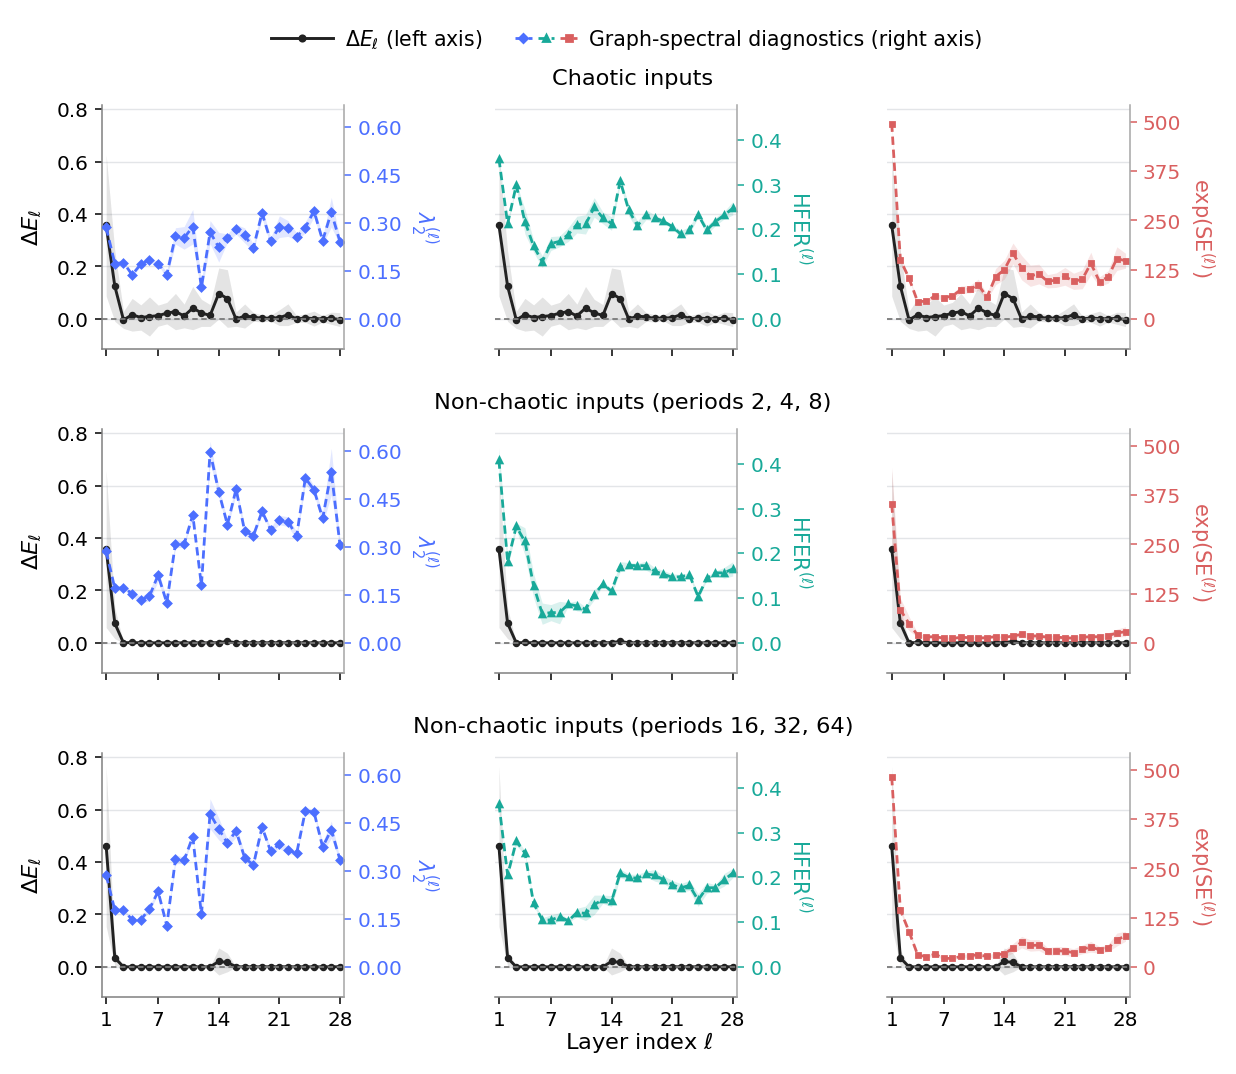

Saved figures/layer_skip_diagnostics.pdf


In [5]:
periodic_figure_path = plot_group_comparison(
    periodic_profiles, "layer_skip_diagnostics.pdf"
)